# World Model Pipeline

This notebook demonstrates the complete pipeline for two world model variants:

**Standard WorldModel** (Sections 1–4):
1. **Data Loading**: Trajectories from local NPZ files or Hugging Face Hub.
2. **Architecture**: Modular WorldModel — CNN/ViT backbone + latent dynamics.
3. **Training**: Multi-step rollout loss with state/risk heads.
4. **Inference & MPC**: Cross-Entropy Method (CEM) planning.

**DinoWM** (Section 5):
5. **DinoWM**: DINOv2-backed world model with a ViT predictor trained in latent space.

| | Standard WM | DinoWM |
|---|---|---|
| Visual backbone | Trainable CNN/ViT | Frozen DINOv2 |
| Prediction target | Pixel + state + risk | Latent embedding (MSE) |
| Data format | `SampleBatch` | `(obs_dict, action, state)` |

In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Ensure project root is in path
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '../..'))
sys.path.append(os.path.join(PROJECT_ROOT, 'src'))

from world_model.data import NPZEpisodeDataset, HFWindowDataset, collate_npz, collate_hf
from world_model.architecture import WorldModel
from world_model.engine.trainer import TrainConfig, rollout_loss
from world_model.mpc import cem_plan, CEMConfig

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

/Users/akashguna/Documents/ELV/NYU_DS_GA_3001/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/akashguna/Documents/ELV/NYU_DS_GA_3001/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Using device: cpu


## 1. Data Loading

The world model can load data from two main sources:
- **Local NPZ Episodes**: Trajectories stored as individual `.npz` files.
- **Hugging Face Hub**: Trajectories hosted as Arrow/Parquet datasets.

### B. Hugging Face Dataloading

Loading lquan9/collect1...
[HFWindowDataset] Attempting to load from Hub: lquan9/collect1


Total segments (windows/episodes): 1032
Total frames in dataset: 51600
Columns: ['episode_id', 'frame_idx', 'image', 'odom_0', 'odom_1', 'odom_2', 'odom_3', 'odom_4', 'odom_5', 'odom_6', 'odom_7', 'odom_8', 'odom_9', 'odom_10', 'odom_11', 'odom_12', 'action_0', 'action_1', 'action_2', 'action_3', 'action_4', 'action_5', 'action_6', 'action_7', 'action_8', 'action_9', 'action_10', 'action_11', 'action_12', 'imu_0', 'imu_1', 'imu_2', 'imu_3', 'imu_4', 'imu_5', 'imu_6', 'imu_7', 'imu_8', 'imu_9', 'depth_mean']
Dimensions: Odom=13, IMU=10, Act=13

Showing reel for Episode 0           (Sequence length: 50 frames)


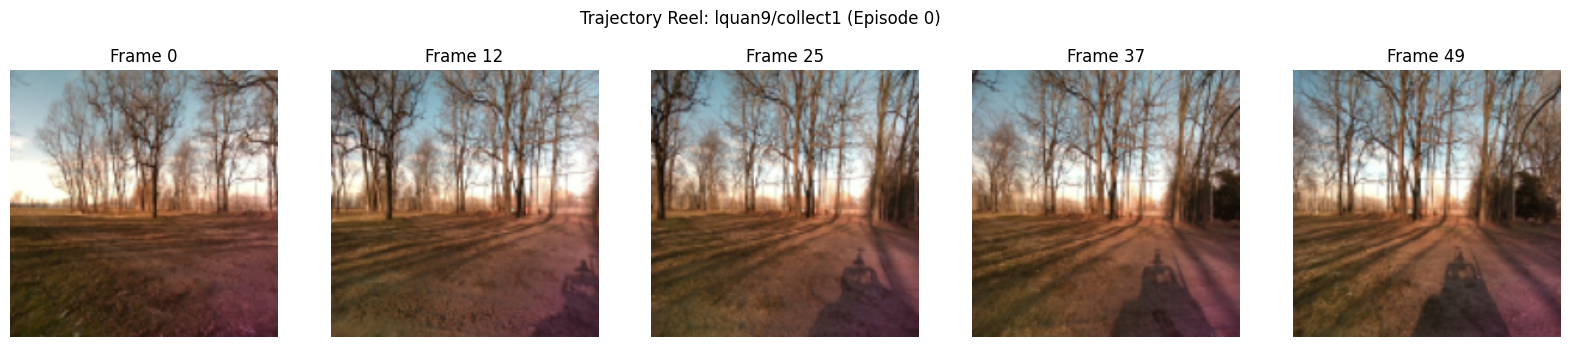

In [2]:
hf_repo = "lquan9/collect1"
ep = 0
try:
    print(f"Loading {hf_repo}...")
    ds_hf = HFWindowDataset(hf_repo, img_size=224)
    
    # Dataset Statistics
    print(f"Total segments (windows/episodes): {len(ds_hf)}")
    print(f"Total frames in dataset: {len(ds_hf._ds)}")
    print(f"Columns: {ds_hf._ds.column_names}")
    print(f"Dimensions: Odom={ds_hf.D_odom}, IMU={ds_hf.D_imu}, Act={ds_hf.D_act}")
    
    window = ds_hf[ep]
    rgb = window["rgb"]
    print(f"\nShowing reel for Episode {ep} \
          (Sequence length: {rgb.shape[0]} frames)")
    
    # Image Reel (show 5 images across the window)
    n_frames = rgb.shape[0]
    indices = [0, n_frames//4, n_frames//2, (3*n_frames)//4, n_frames-1]
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for i, idx in enumerate(indices):
        # rgb is (T, 3, H, W) numpy array
        img = rgb[idx].transpose(1, 2, 0)
        axes[i].imshow(img)
        axes[i].set_title(f"Frame {idx}")
        axes[i].axis('off')
    plt.suptitle(f"Trajectory Reel: {hf_repo} (Episode {ep})")
    plt.show()
except Exception as e:
    print(f"Error loading dataset: {e}")


## 2. World Model Architecture

The `WorldModel` is modular, consisting of a vision encoder, a proprioception encoder, a fusion layer, and latent dynamics.

In [3]:
o_dim = ds_hf.D_odom
i_dim = ds_hf.D_imu
a_dim = ds_hf.D_act

model = WorldModel(
    odom_dim=o_dim,
    imu_dim=i_dim,
    act_dim=a_dim, 
    backbone='dinov2' 
).to(device)

print(model)

/Users/akashguna/Documents/ELV/NYU_DS_GA_3001/external/dino/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/akashguna/Documents/ELV/NYU_DS_GA_3001/external/dino/dinov2/layers/attention.py:34: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/akashguna/Documents/ELV/NYU_DS_GA_3001/external/dino/dinov2/layers/block.py:41: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


WorldModel(
  (vision): DINOv2Encoder(
    (model): DinoVisionTransformer(
      (patch_embed): PatchEmbed(
        (proj): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
        (norm): Identity()
      )
      (blocks): ModuleList(
        (0-11): 12 x NestedTensorBlock(
          (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (attn): MemEffAttention(
            (qkv): Linear(in_features=768, out_features=2304, bias=True)
            (proj): Linear(in_features=768, out_features=768, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
          )
          (ls1): LayerScale()
          (drop_path1): Identity()
          (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (act): GELU(approximate='none')
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
            (drop): Dropout(p=0.0, inplace=False

## 3. Training: Multi-step Rollout

During training, we roll out the latent dynamics for $H$ steps and compare the predicted latents and states with the actual ones.

In [5]:
if 'ds_hf' in locals():
    batch_size = 1
    train_loader = DataLoader(ds_hf, batch_size=batch_size, shuffle=True, collate_fn=collate_hf)

    # Get a single batch from the loader for demonstration
    batch = next(iter(train_loader)) 
    
    cfg = TrainConfig(device=str(device), horizon=8)
    loss, logs = rollout_loss(model, batch, cfg)
    
    print(f"Total Loss: {loss.item():.4f}")
    for k, v in logs.items():
        if k != 'loss':
            print(f"  {k}: {v:.4f}")

Total Loss: 403.4267
  loss_z: 1.9305
  loss_state: 401.3684
  loss_risk: 0.6393


### B. Training Loop

In [6]:
import torch.optim as optim
from torch.utils.data import DataLoader

def train_world_model(model, dataloader, epochs=5, lr=3e-4, device='cuda'):
    model.train()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    cfg = TrainConfig(device=device, lr=lr)
    
    print(f"Starting training for {epochs} epochs on {device}...")
    
    for epoch in range(epochs):
        epoch_loss = 0
        batch_count = 0
        
        for batch in dataloader:
            optimizer.zero_grad()
            
            # Compute multi-step rollout loss
            loss, logs = rollout_loss(model, batch, cfg)
            
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            batch_count += 1
            
            if batch_count % 10 == 0:
                print(f"Epoch {epoch+1}, Batch {batch_count}, Loss: {loss.item():.4f}")
        
        if batch_count > 0:
            avg_loss = epoch_loss / batch_count
            print(f"Epoch {epoch+1} Complete. Average Loss: {avg_loss:.4f}")
        else:
            print(f"No batches processed for Epoch {epoch+1}")

if 'ds_hf' in locals():
    batch_size = 4
    train_loader = DataLoader(ds_hf, batch_size=batch_size, shuffle=True, collate_fn=collate_hf)

train_world_model(model, train_loader, epochs=1, device=str(device))

Starting training for 1 epochs on cpu...


KeyboardInterrupt: 

### C. Model Save/Load

In [ ]:
def save_checkpoint(model, path="world_model_weights.pt"):
    torch.save(model.state_dict(), path)
    print(f"Model weights saved to {path}")

def load_checkpoint(model, path="world_model_weights.pt"):
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device))
        model.eval()
        print(f"Model weights loaded from {path}")
    else:
        print(f"No checkpoint found at {path}")

# Save the current model state
save_checkpoint(model)

# Explicitly load from a previous checkpoint
load_checkpoint(model)

Model weights saved to world_model_weights.pt
Model weights loaded from world_model_weights.pt


## 4. Inference & MPC Planning

We use the Cross-Entropy Method (CEM) to plan a sequence of actions that minimizes a cost function.

In [ ]:
def simple_cost_fn(state_seq, risk_seq, goal):
    # Cost = Distance to goal + risk penalty
    # state_seq[:, -1, :2] assumes first two dimensions are X, Y
    dist = torch.norm(state_seq[:, -1, :2] - goal[:, :2], dim=-1)
    risk_penalty = risk_seq.mean(dim=1) * 100.0
    return dist + risk_penalty

def run_inference(model, batch, device):
    # Ensure we are in eval mode
    model.eval()
    
    # Encode the initial state from the batch
    with torch.no_grad():
        z = model.encode(
            batch.rgb[0, 0:1].to(device), 
            batch.depth[0, 0:1].to(device), 
            batch.odom[0, 0:1].to(device), 
            batch.imu[0, 0:1].to(device)
        )
        z0 = z.z

    goal = torch.tensor([[5.0, 5.0]], device=device)
    cem_cfg = CEMConfig(horizon=15, iters=5, population=100, action_dim=a_dim)

    best_action, best_seq = cem_plan(model, z0, goal, simple_cost_fn, cem_cfg, device)

    print(f"Best initial action: {best_action.cpu().numpy()}")
    print(f"Planned sequence shape: {best_seq.shape}")

if 'batch' in locals():
    # load_checkpoint(model)
    run_inference(model, batch, device)
else:
    print("Please load a data batch in Section 1 to run inference.")

Best initial action: [ 1.3754961   3.2801394  -2.3499172  -0.6222851   2.133698   -1.7349781
  0.76486975  1.0012379  -1.0975953  -1.1717279   0.27629519  0.823419
  2.3760812 ]
Planned sequence shape: torch.Size([15, 13])


---

## 5. DinoWM (DINOv2-based World Model)

DinoWM replaces the trainable CNN/ViT backbone with a **frozen DINOv2** encoder and trains a **ViT predictor** in latent space. Key design choices:

- **No pixel loss** — the predictor is trained with embedding-space MSE only (unless a decoder is attached)
- **Patch-level tokens** — each frame produces `num_patches` feature vectors (e.g. 256 for ViT-S/14 at 224×224)
- **Proprioception & actions as tokens** — mapped to the same embedding dimension and fused via concatenation (`concat_dim=1`) or as extra tokens (`concat_dim=0`)

### A. DinoWM Data Loading

DinoWM uses `HFWindowDataset` in **sample mode** (`sample_mode=True`), which returns fixed-length windows of `sample_k` frames sampled at `frameskip` stride. The `collate_dinowm` collator returns `(obs_dict, action, state)` tuples where `obs_dict` has two keys:
- `"visual"`: `(B, T, 3, H, W)` — RGB frames
- `"proprio"`: `(B, T, D_proprio)` — proprioceptive signal (IMU)

In [7]:
from world_model.data import collate_dinowm, EpisodeDataset

NUM_HIST  = 3    # context frames fed to the predictor
NUM_PRED  = 1    # frames to predict ahead
FRAMESKIP = 5    # temporal stride (sample every 5th raw frame)

hf_repo = "lquan9/collect1"
try:
    print(f"Loading DinoWM dataset: {hf_repo} ...")
    ds_dinowm = HFWindowDataset(
        hf_repo,
        img_size=224,
        frameskip=FRAMESKIP,
        sample_mode=True,           # sample fixed-length windows
        sample_k=NUM_HIST + NUM_PRED,
    )
    print(f"Dataset size (# windows): {len(ds_dinowm)}")
    print(f"Proprio (IMU) dim:        {ds_dinowm.proprio_dim}")
    print(f"Action dim:               {ds_dinowm.action_dim}")

    dinowm_loader = DataLoader(
        ds_dinowm,
        batch_size=2,
        shuffle=True,
        num_workers=0,
        collate_fn=collate_dinowm,   # returns (obs_dict, action, state)
    )

    obs_batch, act_batch, state_batch = next(iter(dinowm_loader))
    print(f"\nBatch contents:")
    print(f"  obs['visual']:   {obs_batch['visual'].shape}   # (B, T, 3, H, W)")
    print(f"  obs['proprio']:  {obs_batch['proprio'].shape}  # (B, T, D_proprio)")
    print(f"  act:             {act_batch.shape}   # (B, T, D_act)")
    print(f"  state:           {state_batch.shape} # (B, T, D_state)")
except Exception as e:
    print(f"Error: {e}")
    raise

Loading DinoWM dataset: lquan9/collect1 ...
[HFWindowDataset] Attempting to load from Hub: lquan9/collect1
Dataset size (# windows): 1032
Proprio (IMU) dim:        10
Action dim:               13

Batch contents:
  obs['visual']:   torch.Size([2, 4, 3, 224, 224])   # (B, T, 3, H, W)
  obs['proprio']:  torch.Size([2, 4, 10])  # (B, T, D_proprio)
  act:             torch.Size([2, 4, 13])   # (B, T, D_act)
  state:           torch.Size([2, 4, 24]) # (B, T, D_state)


### B. DinoWM Architecture

DinoWM assembles four components into the `WM` wrapper:

| Component | Class | Role |
|---|---|---|
| Visual encoder | `DINOv2Encoder` (frozen) | `(B·T, 3, H, W)` → `(B·T, num_patches, emb_dim)` patch tokens |
| Proprio encoder | `ProprioceptiveEmbedding` | `(B, T, D_proprio)` → `(B, T, emb_dim)` per-step token |
| Action encoder | `ProprioceptiveEmbedding` | `(B, T, D_act)` → `(B, T, emb_dim)` per-step token |
| Predictor | `ViTPredictor` | `(B, num_hist·P, dim)` → predicted future tokens |

With `concat_dim=1`, proprio and action embeddings are **tiled across patches and concatenated** along the feature dimension, so the total token dim is `encoder.emb_dim + proprio_emb + action_emb`.

In [8]:
from world_model.backbones.dino import build_dinov2
from world_model.backbones.base import ModelBundle
from world_model.backbones.proprio import ProprioceptiveEmbedding
from world_model.backbones.latentdynamics import ViTPredictor
from world_model.backbones.wm import WM

PROPRIO_EMB_DIM = 10
ACTION_EMB_DIM  = 10
CONCAT_DIM      = 1   # concat proprio/action along feature dim (mode used in training)

# --- 1. DINOv2 visual encoder (frozen) ---
dino_bundle = build_dinov2(model_name="dinov2_vits14")
encoder = dino_bundle.model if isinstance(dino_bundle, ModelBundle) else dino_bundle
encoder = encoder.to(device)
for p in encoder.parameters():
    p.requires_grad = False
print(f"DINOv2 encoder:   emb_dim={encoder.emb_dim},  num_patches={encoder.num_patches}")

# --- 2. Proprio encoder: IMU → embedding token ---
proprio_encoder = ProprioceptiveEmbedding(
    num_frames=1, tubelet_size=1,
    in_chans=ds_dinowm.proprio_dim,
    emb_dim=PROPRIO_EMB_DIM,
).to(device)

# --- 3. Action encoder: action → embedding token ---
action_encoder = ProprioceptiveEmbedding(
    num_frames=1, tubelet_size=1,
    in_chans=ds_dinowm.action_dim,
    emb_dim=ACTION_EMB_DIM,
).to(device)

# --- 4. ViT predictor ---
# With concat_dim=1, token dim expands to encoder.emb_dim + proprio_emb + action_emb
num_patches   = encoder.num_patches        # e.g. 256 for ViT-S/14 on 224x224
predictor_dim = encoder.emb_dim + (PROPRIO_EMB_DIM + ACTION_EMB_DIM) * CONCAT_DIM

predictor = ViTPredictor(
    num_patches = num_patches,
    num_frames  = NUM_HIST,
    dim         = predictor_dim,
    depth       = 6,
    heads       = 16,
    mlp_dim     = 2048,
    dropout     = 0.1,
    emb_dropout = 0.0,
    pool        = "mean",
).to(device)
print(f"ViTPredictor:     dim={predictor_dim},  sequence_len={NUM_HIST * num_patches}")

# --- 5. Full WM wrapper ---
dinowm = WM(
    image_size         = 224,
    num_hist           = NUM_HIST,
    num_pred           = NUM_PRED,
    encoder            = encoder,
    proprio_encoder    = proprio_encoder,
    action_encoder     = action_encoder,
    predictor          = predictor,
    decoder            = None,          # no image decoder in this demo
    proprio_dim        = PROPRIO_EMB_DIM,
    action_dim         = ACTION_EMB_DIM,
    concat_dim         = CONCAT_DIM,
    num_action_repeat  = 1,
    num_proprio_repeat = 1,
    raw_action_dim     = ds_dinowm.action_dim,
    train_encoder      = False,
    train_predictor    = True,
    train_decoder      = False,
).to(device)

total_p    = sum(p.numel() for p in dinowm.parameters())
trainable_p = sum(p.numel() for p in dinowm.parameters() if p.requires_grad)
print(f"\nWM total params:     {total_p:,}")
print(f"WM trainable params: {trainable_p:,}  (encoder is frozen)")

DINOv2 encoder:   emb_dim=384,  num_patches=256
ViTPredictor:     dim=404,  sequence_len=768
num_action_repeat: 1
num_proprio_repeat: 1
proprio encoder: ProprioceptiveEmbedding(
  (patch_embed): Conv1d(10, 10, kernel_size=(1,), stride=(1,))
)
action encoder: ProprioceptiveEmbedding(
  (patch_embed): Conv1d(13, 10, kernel_size=(1,), stride=(1,))
)
proprio_dim: 10, after repeat: 10
action_dim: 10, after repeat: 10
emb_dim: 404
Model emb_dim:  404

WM total params:     42,324,095
WM trainable params: 20,267,519  (encoder is frozen)


### C. DinoWM Forward Pass

`WM.forward(obs, act)` runs the full encode → predict → loss pipeline:
1. Encodes all `num_hist + num_pred` frames into patch tokens
2. Predicts the `num_hist` future tokens from the first `num_hist` context tokens
3. Computes embedding-space MSE between predicted and target tokens (visual + proprio; action is excluded from the loss)

With `decoder=None`, `visual_pred` is `None` — there is no pixel reconstruction.

In [9]:
dinowm.train()
obs_gpu = {k: v.float().to(device) for k, v in obs_batch.items()}
act_gpu = act_batch.float().to(device)

with torch.no_grad():
    z_pred, visual_pred, visual_reconstructed, loss, loss_components = dinowm(obs_gpu, act_gpu)

print(f"Forward pass complete.")
print(f"  Total loss: {loss.item():.4f}  (embedding-space MSE)")
for k, v in loss_components.items():
    val = v.item() if isinstance(v, torch.Tensor) else float(v)
    print(f"  {k}: {val:.4f}")

if z_pred is not None:
    B, T, P, D = z_pred.shape
    print(f"\n  z_pred shape: {z_pred.shape}")
    print(f"    -> (batch={B}, time={T}, patches={P}, emb_dim={D})")
    print(f"  visual_pred: {visual_pred}  (None — no decoder in this demo)")

Forward pass complete.
  Total loss: 4.2831  (embedding-space MSE)
  z_loss: 4.2831
  z_visual_loss: 4.3471
  z_proprio_loss: 1.8258
  loss: 4.2831

  z_pred shape: torch.Size([2, 3, 256, 404])
    -> (batch=2, time=3, patches=256, emb_dim=404)
  visual_pred: None  (None — no decoder in this demo)


### D. DinoWM Open-Loop Rollout

`WM.rollout(obs_0, act)` autoregressively predicts future latent states:
- **Input**: `obs_0` — dict with the first `num_hist` context frames
- **Input**: `act` — actions for context frames + future rollout steps
- **Output**: `z_obses` (dict of latent visual/proprio tokens), `z_full` (full token sequence)

This is the core primitive for downstream planning and evaluation.

In [10]:
ROLLOUT_STEPS = 4

dinowm.eval()
with torch.no_grad():
    # Context: first num_hist frames from the first batch item
    obs_0 = {k: v[:1, :NUM_HIST].float().to(device) for k, v in obs_batch.items()}

    # Actions: context actions + zero-filled future placeholders
    act_hist   = act_batch[:1, :NUM_HIST].float().to(device)
    act_future = torch.zeros(1, ROLLOUT_STEPS, ds_dinowm.action_dim, device=device)
    act_full   = torch.cat([act_hist, act_future], dim=1)  # (1, num_hist + ROLLOUT_STEPS, D_act)

    z_obses, z_full = dinowm.rollout(obs_0, act_full)

T_total = z_full.shape[1]
B, T, P, D = z_obses["visual"].shape
print(f"Open-loop rollout over {ROLLOUT_STEPS} future steps:")
print(f"  Context frames:          {NUM_HIST}")
print(f"  Predicted future frames: {ROLLOUT_STEPS}")
print(f"  Total token sequence:    {T_total}")
print(f"  z_obses['visual'] shape: {z_obses['visual'].shape}")
print(f"    -> (batch={B}, time={T}, patches={P}, emb_dim={D})")

Open-loop rollout over 4 future steps:
  Context frames:          3
  Predicted future frames: 4
  Total token sequence:    8
  z_obses['visual'] shape: torch.Size([1, 8, 256, 384])
    -> (batch=1, time=8, patches=256, emb_dim=384)


In [11]:
# Cleanup: Flush model and clear system resources
import torch
import gc

# Delete large objects
if 'model' in locals():
    print("Deleting model...")
    del model

if 'train_loader' in locals():
    print("Deleting train_loader...")
    del train_loader

if 'ds_hf' in locals():
    print("Deleting ds_hf...")
    del ds_hf

# Force garbage collection and clear GPU cache
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("System resources cleared.")

Deleting model...
Deleting train_loader...
Deleting ds_hf...
System resources cleared.
